# CLEAR on CheXpert dataset

In [1]:
# Imports and configs
import copy
import gc
import json
import os
import random
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import (accuracy_score, average_precision_score,
                             confusion_matrix, precision_recall_curve,
                             precision_recall_fscore_support, roc_auc_score, roc_curve)
from sklearn.model_selection import GroupShuffleSplit
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset

SEED = 42
NUM_SEEDS = 20
MAX_EPOCHS = 200
PATIENCE = 10
IMAGE_BATCH_SIZE = 32
HEAD_BATCH_SIZE = 512
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 0.0
NUM_WORKERS = 4
CONCEPT_CHUNK = 4096
LABELS = ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Pleural Effusion']
UNCERTAIN = {'Atelectasis': 1, 'Cardiomegaly': 0, 'Consolidation': 0,
             'Edema': 1, 'Pleural Effusion': 1}
INPUT = Path('/kaggle/input')
WORK = Path('/kaggle/working')
RESULTS = WORK / 'clear_chexpert_results'
RESULTS.mkdir(parents=True, exist_ok=True)
RUN_START = time.perf_counter()
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
if not torch.cuda.is_available():
    raise RuntimeError('Select a GPU accelerator in Kaggle Notebook settings.')
DEVICE = torch.device('cuda:0')
print('GPU:', ', '.join(torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())))

GPU: Tesla T4, Tesla T4


In [2]:
# Install the official CLEAR package
REPO = WORK / 'CLEAR_official'
if not (REPO / 'src/clear/hub.py').is_file():
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/peterhan91/CLEAR.git', str(REPO)], check=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(REPO), 'timm'], check=True)
sys.path.insert(0, str(REPO / 'src'))
from clear import ConceptBank, ZeroShotPipeline, load_pretrained
CODE_REVISION = subprocess.check_output(['git', '-C', str(REPO), 'rev-parse', 'HEAD'], text=True).strip()
print('CLEAR code revision:', CODE_REVISION[:12])


Cloning into '/kaggle/working/CLEAR_official'...


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.7 MB/s eta 0:00:00
CLEAR code revision: 57d2eae57dda


In [3]:
# Locate CheXpert and download any missing official CLEAR assets
from huggingface_hub import HfApi, hf_hub_download

DATA_ROOTS = [p.parent for p in INPUT.rglob('train.csv')
              if (p.parent / 'valid.csv').is_file()
              and (p.parent / 'train').is_dir()
              and (p.parent / 'valid').is_dir()]
if len(DATA_ROOTS) != 1:
    raise FileNotFoundError('Attach one CheXpert dataset containing train.csv, valid.csv, train/ and valid/.')
DATA_ROOT = DATA_ROOTS[0]
ASSET_NAMES = ['best_model.pt', 'mimic_concepts.csv',
               'concept_embeddings_368294.pt', 'concepts_embeddings_sfr_mistral.pickle']
attached = {name: list(INPUT.rglob(name)) for name in ASSET_NAMES}
missing = [name for name in ASSET_NAMES if not attached[name]]
HUB_REVISION = None
if missing:
    HUB_REVISION = HfApi().model_info('peterhan91/CLEAR').sha
ASSETS = {}
for name in ASSET_NAMES:
    if len(attached[name]) > 1:
        raise ValueError(f'Multiple attached files named {name}; keep one CLEAR asset set.')
    ASSETS[name] = attached[name][0] if attached[name] else Path(
        hf_hub_download(repo_id='peterhan91/CLEAR', filename=name, revision=HUB_REVISION)
    )
print('CheXpert:', DATA_ROOT)
print('CLEAR assets:', ', '.join(f'{name} ({ASSETS[name].stat().st_size / 1e9:.2f} GB)'
                                for name in ASSET_NAMES))
print('Hugging Face revision:', HUB_REVISION or 'attached local assets')


best_model.pt: reconstructing file:   0%|          |  0.00B /  603MB            

best_model.pt: downloading bytes:           |  0.00B            

mimic_concepts.csv: reconstructing file:   0%|          |  0.00B / 22.2MB            

mimic_concepts.csv: downloading bytes:           |  0.00B            

concept_embeddings_368294.pt: reconstructing file:   0%|          |  0.00B / 1.13GB            

concept_embeddings_368294.pt: downloading bytes:           |  0.00B            

concepts_embeddings_sfr_mistral.pickle: reconstructing file:   0%|          |  0.00B / 6.05GB            

concepts_embeddings_sfr_mistral.pickle: downloading bytes:           |  0.00B            

CheXpert: /kaggle/input/datasets/ashery/chexpert
CLEAR assets: best_model.pt (0.60 GB), mimic_concepts.csv (0.02 GB), concept_embeddings_368294.pt (1.13 GB), concepts_embeddings_sfr_mistral.pickle (6.05 GB)
Hugging Face revision: 142f169c8b006b0f28cf55c6a237c3003db5ed8f


In [4]:
# Match GLoRIA's five labels and patient-level CheXpert split
def clean_labels(frame, public_validation=False):
    frame = frame.loc[frame['Frontal/Lateral'] == 'Frontal'].copy()
    frame['patient_id'] = frame['Path'].str.extract(r'(patient\d+)')
    if frame['patient_id'].isna().any():
        raise ValueError('Some CheXpert paths do not contain a patient ID.')
    for label in LABELS:
        values = pd.to_numeric(frame[label], errors='coerce')
        if public_validation:
            if not values.isin([0, 1]).all():
                raise ValueError(f'Public validation has non-binary values for {label}.')
        else:
            values = values.fillna(0).replace(-1, UNCERTAIN[label])
        frame[label] = values.astype('float32')
    return frame.reset_index(drop=True)

all_train = clean_labels(pd.read_csv(DATA_ROOT / 'train.csv'))
test_df = clean_labels(pd.read_csv(DATA_ROOT / 'valid.csv'), public_validation=True)
split = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=SEED)
train_rows, val_rows = next(split.split(all_train, groups=all_train['patient_id']))
train_df = all_train.iloc[train_rows].reset_index(drop=True)
val_df = all_train.iloc[val_rows].reset_index(drop=True)

def image_path(raw_path):
    parts = Path(raw_path).parts
    folder = 'train' if 'train' in parts else 'valid'
    return DATA_ROOT.joinpath(*parts[parts.index(folder):])

for frame in (train_df, val_df, test_df):
    frame['image_path'] = frame['Path'].map(image_path)
for name, frame in [('Train', train_df), ('Internal validation', val_df), ('Public validation', test_df)]:
    print(f'{name}: {len(frame):,} images; {frame.patient_id.nunique():,} patients')
print('Positive counts:')
print(pd.DataFrame({'train': train_df[LABELS].sum().astype(int),
                    'validation': val_df[LABELS].sum().astype(int),
                    'public': test_df[LABELS].sum().astype(int)}).to_string())


Train: 171,927 images; 58,080 patients
Internal validation: 19,100 images; 6,454 patients
Public validation: 202 images; 200 patients
Positive counts:
                  train  validation  public
Atelectasis       53640        5943      75
Cardiomegaly      20994        2391      66
Consolidation     11688        1295      32
Edema             55441        6052      42
Pleural Effusion  77912        8565      64


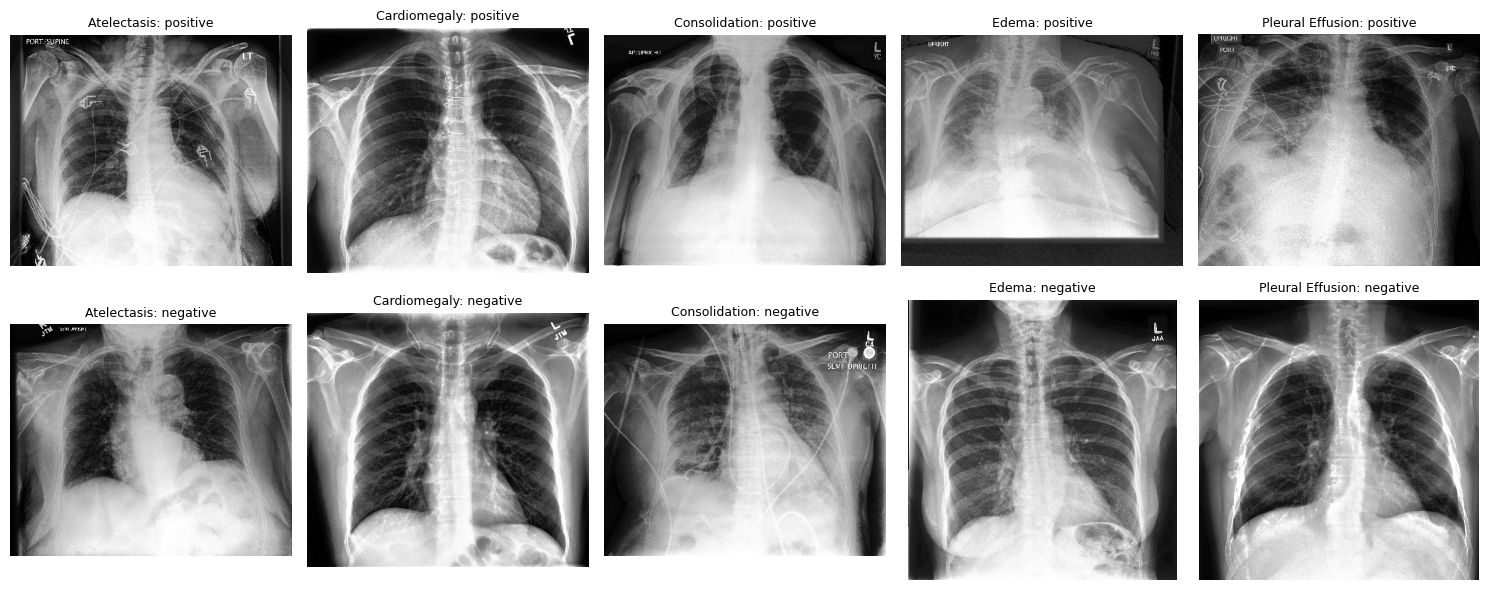

In [5]:
# Display positive and negative training examples
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for j, label in enumerate(LABELS):
    for row, target in enumerate([1, 0]):
        choices = train_df.loc[train_df[label] == target]
        sample = choices.sample(n=1, random_state=SEED + j + row).iloc[0]
        with Image.open(sample['image_path']) as image:
            axes[row, j].imshow(image.convert('L'), cmap='gray')
        axes[row, j].set_title(f'{label}: {"positive" if target else "negative"}', fontsize=9)
        axes[row, j].axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'sample_images.png', dpi=160)
plt.show()
plt.close(fig)


In [6]:
# Load CLEAR's official checkpoint and 448-pixel image transform
model, preprocess = load_pretrained(checkpoint_path=ASSETS['best_model.pt'], device=DEVICE)
model.requires_grad_(False).eval()

class CLEARImages(Dataset):
    def __init__(self, frame):
        self.paths = frame['image_path'].tolist()
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            return preprocess(image)

class ImageEncoder(nn.Module):
    def __init__(self, clear_model):
        super().__init__()
        self.clear_model = clear_model
    def forward(self, images):
        return self.clear_model.encode_image(images)

encoder = ImageEncoder(model).eval()
if torch.cuda.device_count() > 1:
    encoder = nn.DataParallel(encoder)

def image_loader(frame):
    return DataLoader(CLEARImages(frame), batch_size=IMAGE_BATCH_SIZE, shuffle=False,
                      num_workers=NUM_WORKERS, pin_memory=True,
                      persistent_workers=NUM_WORKERS > 0)

small_batch = next(iter(image_loader(train_df.head(2)))).to(DEVICE)
with torch.inference_mode(), torch.autocast('cuda', dtype=torch.float16):
    small_features = encoder(small_batch)
if small_features.shape != (2, 768):
    raise ValueError(f'Unexpected CLEAR image feature shape: {tuple(small_features.shape)}')
print('CLEAR image features:', tuple(small_features.shape), '| input:', tuple(small_batch.shape))
del small_batch, small_features


Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


CLEAR image features: (2, 768) | input: (2, 3, 448, 448)


In [7]:
# Load and align the complete 368,294-concept bank
concept_table = pd.read_csv(ASSETS['mimic_concepts.csv'])
if 'concept' not in concept_table or 'concept_idx' not in concept_table:
    raise ValueError('CLEAR concept CSV must contain concept and concept_idx columns.')
indices = concept_table['concept_idx'].to_numpy()
if not np.array_equal(indices, np.arange(len(indices))):
    raise ValueError('CLEAR concepts must be ordered by contiguous concept_idx values.')
bank = ConceptBank.from_files(
    ASSETS['mimic_concepts.csv'],
    clip_embeddings_path=ASSETS['concept_embeddings_368294.pt'],
    llm_embeddings_path=ASSETS['concepts_embeddings_sfr_mistral.pickle'],
    allow_unsafe_pickle=True,
)
bank.concepts = tuple(concept_table['concept'].astype(str))
if bank.num_concepts != 368294 or bank.clip_embeddings.shape != (368294, 768) \
        or bank.llm_embeddings.shape != (368294, 4096):
    raise ValueError('CLEAR concept assets have unexpected or misaligned shapes.')
print('Concept bank:', bank.num_concepts, '| text features:', bank.clip_embeddings.shape,
      '| LLM embeddings:', bank.llm_embeddings.shape)
del concept_table
gc.collect()


/kaggle/working/CLEAR_official/src/clear/concepts.py:298: RuntimeWarning: Unpickling /root/.cache/huggingface/hub/models--peterhan91--CLEAR/snapshots/142f169c8b006b0f28cf55c6a237c3003db5ed8f/concepts_embeddings_sfr_mistral.pickle; only trusted pickle files should be loaded.
  _load_array(


Concept bank: 368294 | text features: (368294, 768) | LLM embeddings: (368294, 4096)


0

In [8]:
# Precompute the full CLEAR projection
projection_start = time.perf_counter()
projection = torch.zeros((768, 4096), device=DEVICE, dtype=torch.float32)
with torch.inference_mode():
    for start in range(0, bank.num_concepts, CONCEPT_CHUNK):
        stop = min(start + CONCEPT_CHUNK, bank.num_concepts)
        text_chunk = torch.from_numpy(bank.clip_embeddings[start:stop]).to(DEVICE)
        llm_chunk = torch.from_numpy(bank.llm_embeddings[start:stop]).to(DEVICE)
        projection.add_(F.normalize(text_chunk, dim=1).T @ llm_chunk)
        del text_chunk, llm_chunk
projection_seconds = time.perf_counter() - projection_start
torch.save(projection.cpu(), RESULTS / 'clear_projection.pt')

reference = ZeroShotPipeline(model, bank, concept_chunk_size=8192, device=DEVICE)
with Image.open(train_df.iloc[0]['image_path']) as image:
    check_image = preprocess(image).unsqueeze(0).to(DEVICE)
with torch.inference_mode():
    image_feature = F.normalize(model.encode_image(check_image).float(), dim=-1)
    official_output = reference.project_to_concept_space(image_feature)
    fast_output = F.normalize(image_feature @ projection, dim=-1)
max_difference = (official_output - fast_output).abs().max().item()
if max_difference > 1e-3:
    raise RuntimeError(f'CLEAR projection check failed: maximum difference {max_difference:.6f}')
print(f'Full projection verified: maximum difference {max_difference:.6f}; '
      f'precomputation {projection_seconds / 60:.1f} minutes')
del reference, check_image, image_feature, official_output, fast_output
gc.collect()


Full projection verified: maximum difference 0.000000; precomputation 0.0 minutes


9

In [9]:
# Extract frozen 4,096-dimensional CLEAR concept features for all three splits
def extract_features(frame, name):
    path = RESULTS / f'{name}_features.npy'
    vectors = np.lib.format.open_memmap(path, mode='w+', dtype='float32',
                                         shape=(len(frame), 4096))
    start_time = time.perf_counter()
    offset = 0
    with torch.inference_mode():
        for batch in image_loader(frame):
            batch = batch.to(DEVICE, non_blocking=True)
            with torch.autocast('cuda', dtype=torch.float16):
                image_features = encoder(batch)
            image_features = F.normalize(image_features.float(), dim=-1)
            concept_features = F.normalize(image_features @ projection, dim=-1)
            count = len(batch)
            vectors[offset:offset + count] = concept_features.cpu().numpy()
            offset += count
    vectors.flush()
    minutes = (time.perf_counter() - start_time) / 60
    print(f'{name}: {offset:,} images | {minutes:.1f} min | {path.name}')
    return vectors, minutes

train_x, train_minutes = extract_features(train_df, 'train')
val_x, val_minutes = extract_features(val_df, 'validation')
test_x, test_minutes = extract_features(test_df, 'public_validation')
train_y = train_df[LABELS].to_numpy(dtype='float32')
val_y = val_df[LABELS].to_numpy(dtype='float32')
test_y = test_df[LABELS].to_numpy(dtype='float32')


train: 171,927 images | 31.7 min | train_features.npy
validation: 19,100 images | 3.6 min | validation_features.npy
public_validation: 202 images | 0.1 min | public_validation_features.npy


In [10]:
# Train 20 independent linear heads
def head_loader(features, labels, shuffle=False, generator=None):
    dataset = TensorDataset(torch.from_numpy(features), torch.from_numpy(labels))
    return DataLoader(dataset, batch_size=HEAD_BATCH_SIZE, shuffle=shuffle,
                      generator=generator, num_workers=0, pin_memory=True)

val_loader = head_loader(val_x, val_y)
loss_fn = nn.BCEWithLogitsLoss()
all_history = []
seed_records = []
training_start = time.perf_counter()
for seed in range(SEED, SEED + NUM_SEEDS):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    generator = torch.Generator().manual_seed(seed)
    train_loader = head_loader(train_x, train_y, shuffle=True, generator=generator)
    head = nn.Linear(4096, len(LABELS)).to(DEVICE)
    optimizer = torch.optim.Adam(head.parameters(), lr=LEARNING_RATE,
                                 weight_decay=WEIGHT_DECAY)
    best_auc, best_epoch, stale = -1.0, 0, 0
    seed_start = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        head.train()
        train_total = 0.0
        for features, labels in train_loader:
            features = features.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(head(features), labels)
            loss.backward()
            optimizer.step()
            train_total += loss.item() * len(features)
        head.eval()
        val_total = 0.0
        val_prob_batches = []
        with torch.inference_mode():
            for features, labels in val_loader:
                features = features.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)
                logits = head(features)
                val_total += loss_fn(logits, labels).item() * len(features)
                val_prob_batches.append(logits.sigmoid().cpu().numpy())
        val_prob_epoch = np.concatenate(val_prob_batches)
        val_aucs = [roc_auc_score(val_y[:, j], val_prob_epoch[:, j])
                    if len(np.unique(val_y[:, j])) == 2 else np.nan
                    for j in range(len(LABELS))]
        val_auc = float(np.nanmean(val_aucs))
        train_loss = train_total / len(train_df)
        val_loss = val_total / len(val_df)
        all_history.append({'seed': seed, 'epoch': epoch, 'train_loss': train_loss,
                            'val_loss': val_loss, 'val_macro_auroc': val_auc})
        if val_auc > best_auc:
            best_auc, best_epoch, stale = val_auc, epoch, 0
            torch.save(head.state_dict(), RESULTS / f'best_head_seed_{seed}.pt')
        else:
            stale += 1
        print(f'Seed {seed - SEED + 1:02d}/{NUM_SEEDS} | epoch {epoch:03d}/{MAX_EPOCHS} | '
              f'train {train_loss:.4f} | val {val_loss:.4f} | val AUROC {val_auc:.3f}')
        if stale >= PATIENCE:
            print(f'Seed {seed}: early stop at epoch {epoch}; best epoch {best_epoch}.')
            break
    seed_minutes = (time.perf_counter() - seed_start) / 60
    seed_records.append({'seed': seed, 'best_epoch': best_epoch,
                         'best_val_macro_auroc': best_auc,
                         'head_training_minutes': seed_minutes})
    del train_loader, head, optimizer
    torch.cuda.empty_cache()

training_minutes = (time.perf_counter() - training_start) / 60
representative = max(seed_records, key=lambda row: row['best_val_macro_auroc'])
representative_seed = representative['seed']
best_epoch = representative['best_epoch']
history = [row for row in all_history if row['seed'] == representative_seed]
head = nn.Linear(4096, len(LABELS)).to(DEVICE)
head.load_state_dict(torch.load(RESULTS / f'best_head_seed_{representative_seed}.pt',
                                map_location=DEVICE, weights_only=True))
head.eval()
torch.save(head.state_dict(), RESULTS / 'best_head.pt')
print(f'All seeds finished in {training_minutes:.1f} minutes. '
      f'Representative seed {representative_seed}: validation AUROC '
      f'{representative["best_val_macro_auroc"]:.3f} at epoch {best_epoch}.')

Seed 01/20 | epoch 001/200 | train 0.5995 | val 0.5467 | val AUROC 0.614
Seed 01/20 | epoch 002/200 | train 0.5224 | val 0.5046 | val AUROC 0.650
Seed 01/20 | epoch 003/200 | train 0.4922 | val 0.4833 | val AUROC 0.673
Seed 01/20 | epoch 004/200 | train 0.4754 | val 0.4699 | val AUROC 0.690
Seed 01/20 | epoch 005/200 | train 0.4643 | val 0.4605 | val AUROC 0.703
Seed 01/20 | epoch 006/200 | train 0.4564 | val 0.4536 | val AUROC 0.712
Seed 01/20 | epoch 007/200 | train 0.4503 | val 0.4481 | val AUROC 0.720
Seed 01/20 | epoch 008/200 | train 0.4455 | val 0.4438 | val AUROC 0.726
Seed 01/20 | epoch 009/200 | train 0.4416 | val 0.4400 | val AUROC 0.732
Seed 01/20 | epoch 010/200 | train 0.4383 | val 0.4369 | val AUROC 0.737
Seed 01/20 | epoch 011/200 | train 0.4356 | val 0.4345 | val AUROC 0.741
Seed 01/20 | epoch 012/200 | train 0.4332 | val 0.4323 | val AUROC 0.745
Seed 01/20 | epoch 013/200 | train 0.4312 | val 0.4302 | val AUROC 0.749
Seed 01/20 | epoch 014/200 | train 0.4295 | val 0.4

In [11]:
# Evaluate every seed
def predict(features, model):
    parts = []
    with torch.inference_mode():
        for start in range(0, len(features), 4096):
            batch = torch.from_numpy(np.asarray(features[start:start + 4096])).to(DEVICE)
            parts.append(model(batch).sigmoid().cpu().numpy())
    return np.concatenate(parts)

def choose_thresholds(probabilities):
    chosen = {}
    for j, label in enumerate(LABELS):
        precision, recall, choices = precision_recall_curve(val_y[:, j], probabilities[:, j])
        f1_values = 2 * precision[:-1] * recall[:-1] / np.maximum(
            precision[:-1] + recall[:-1], 1e-12)
        chosen[label] = float(choices[np.argmax(f1_values)])
    return chosen

evaluation_start = time.perf_counter()
metric_rows = []
predictions = None
for record in seed_records:
    seed = record['seed']
    head.load_state_dict(torch.load(RESULTS / f'best_head_seed_{seed}.pt',
                                    map_location=DEVICE, weights_only=True))
    head.eval()
    current_val_probs = predict(val_x, head)
    current_thresholds = choose_thresholds(current_val_probs)
    current_test_probs = predict(test_x, head)
    for j, label in enumerate(LABELS):
        truth = test_y[:, j].astype(int)
        probability = current_test_probs[:, j]
        predicted = (probability >= current_thresholds[label]).astype(int)
        precision, recall, f1, _ = precision_recall_fscore_support(
            truth, predicted, average='binary', zero_division=0)
        metric_rows.append({
            'seed': seed, 'label': label,
            'AUROC': roc_auc_score(truth, probability) if len(np.unique(truth)) == 2 else np.nan,
            'AUPRC': average_precision_score(truth, probability) if truth.sum() else np.nan,
            'accuracy': accuracy_score(truth, predicted),
            'precision': precision, 'recall': recall, 'F1': f1,
            'threshold': current_thresholds[label], 'positive_count': int(truth.sum()),
        })
    if seed == representative_seed:
        val_probs = current_val_probs
        thresholds = current_thresholds
        test_probs = current_test_probs
        predictions = test_df[['Path', 'patient_id']].copy()
        for j, label in enumerate(LABELS):
            predictions[f'target_{label}'] = test_y[:, j].astype(int)
            predictions[f'probability_{label}'] = test_probs[:, j]
            predictions[f'prediction_{label}'] = (
                test_probs[:, j] >= thresholds[label]).astype(int)
    seed_metrics = pd.DataFrame(metric_rows).loc[lambda frame: frame.seed == seed]
    record['public_macro_auroc'] = float(seed_metrics.AUROC.mean())
    print(f'Seed {seed}: public-validation macro AUROC '
          f'{record["public_macro_auroc"]:.3f}')

evaluation_seconds = time.perf_counter() - evaluation_start
head.load_state_dict(torch.load(RESULTS / 'best_head.pt',
                                map_location=DEVICE, weights_only=True))
head.eval()
metrics_by_seed_df = pd.DataFrame(metric_rows)
aggregate_metrics_df = metrics_by_seed_df.groupby('label', sort=False)[
    ['AUROC', 'AUPRC', 'accuracy', 'precision', 'recall', 'F1', 'threshold']
].agg(['mean', 'std'])
metrics_df = metrics_by_seed_df.loc[
    metrics_by_seed_df.seed == representative_seed].set_index('label')
metrics = metrics_df.to_dict(orient='index')
seed_summary_df = pd.DataFrame(seed_records)
macro_mean = seed_summary_df.public_macro_auroc.mean()
macro_std = seed_summary_df.public_macro_auroc.std()
print('Public-validation metrics across 20 seeds (mean ± standard deviation):')
print(aggregate_metrics_df.round(3).to_string())
print(f'Macro AUROC: {macro_mean:.3f} ± {macro_std:.3f}')
print(f'Representative seed {representative_seed} is used for figures and attribution.')

Seed 42: public-validation macro AUROC 0.876
Seed 43: public-validation macro AUROC 0.877
Seed 44: public-validation macro AUROC 0.877
Seed 45: public-validation macro AUROC 0.877
Seed 46: public-validation macro AUROC 0.876
Seed 47: public-validation macro AUROC 0.877
Seed 48: public-validation macro AUROC 0.876
Seed 49: public-validation macro AUROC 0.876
Seed 50: public-validation macro AUROC 0.876
Seed 51: public-validation macro AUROC 0.877
Seed 52: public-validation macro AUROC 0.876
Seed 53: public-validation macro AUROC 0.876
Seed 54: public-validation macro AUROC 0.876
Seed 55: public-validation macro AUROC 0.877
Seed 56: public-validation macro AUROC 0.877
Seed 57: public-validation macro AUROC 0.876
Seed 58: public-validation macro AUROC 0.876
Seed 59: public-validation macro AUROC 0.877
Seed 60: public-validation macro AUROC 0.877
Seed 61: public-validation macro AUROC 0.877
Public-validation metrics across 20 seeds (mean ± standard deviation):
                  AUROC      

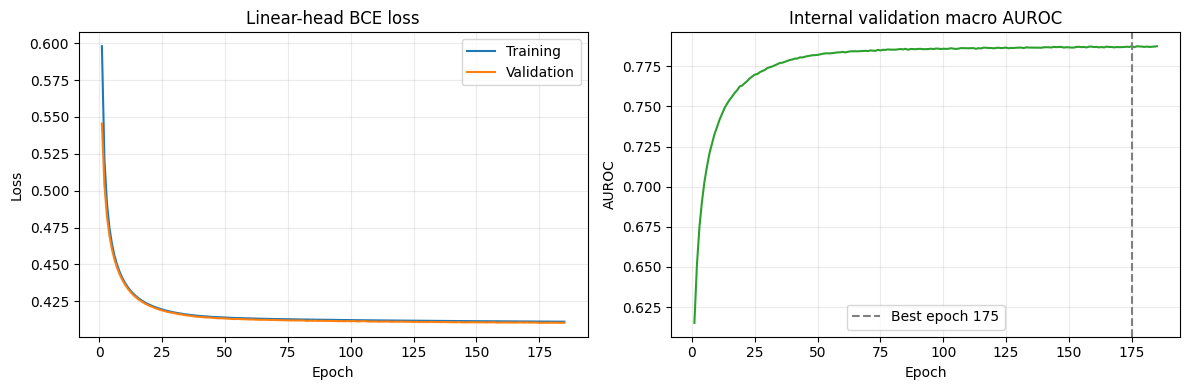

In [12]:
# Plot training and validation curves
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df.epoch, history_df.train_loss, label='Training')
axes[0].plot(history_df.epoch, history_df.val_loss, label='Validation')
axes[0].set(title='Linear-head BCE loss', xlabel='Epoch', ylabel='Loss')
axes[0].legend()
axes[1].plot(history_df.epoch, history_df.val_macro_auroc, color='tab:green')
axes[1].axvline(best_epoch, color='gray', linestyle='--', label=f'Best epoch {best_epoch}')
axes[1].set(title='Internal validation macro AUROC', xlabel='Epoch', ylabel='AUROC')
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RESULTS / 'learning_curves.png', dpi=180)
plt.show()
plt.close(fig)

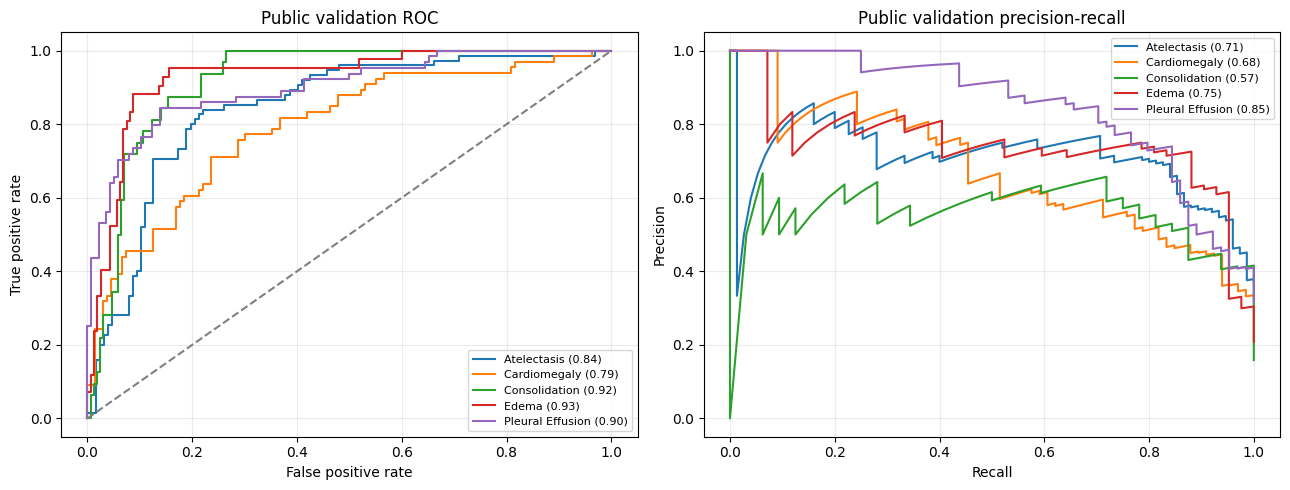

In [13]:
# Plot ROC and precision-recall curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for j, label in enumerate(LABELS):
    truth = test_y[:, j].astype(int)
    if len(np.unique(truth)) < 2:
        continue
    fpr, tpr, _ = roc_curve(truth, test_probs[:, j])
    precision, recall, _ = precision_recall_curve(truth, test_probs[:, j])
    axes[0].plot(fpr, tpr, label=f'{label} ({metrics[label]["AUROC"]:.2f})')
    axes[1].plot(recall, precision, label=f'{label} ({metrics[label]["AUPRC"]:.2f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(title='Public validation ROC', xlabel='False positive rate', ylabel='True positive rate')
axes[1].set(title='Public validation precision-recall', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / 'roc_pr_curves.png', dpi=180)
plt.show()
plt.close(fig)


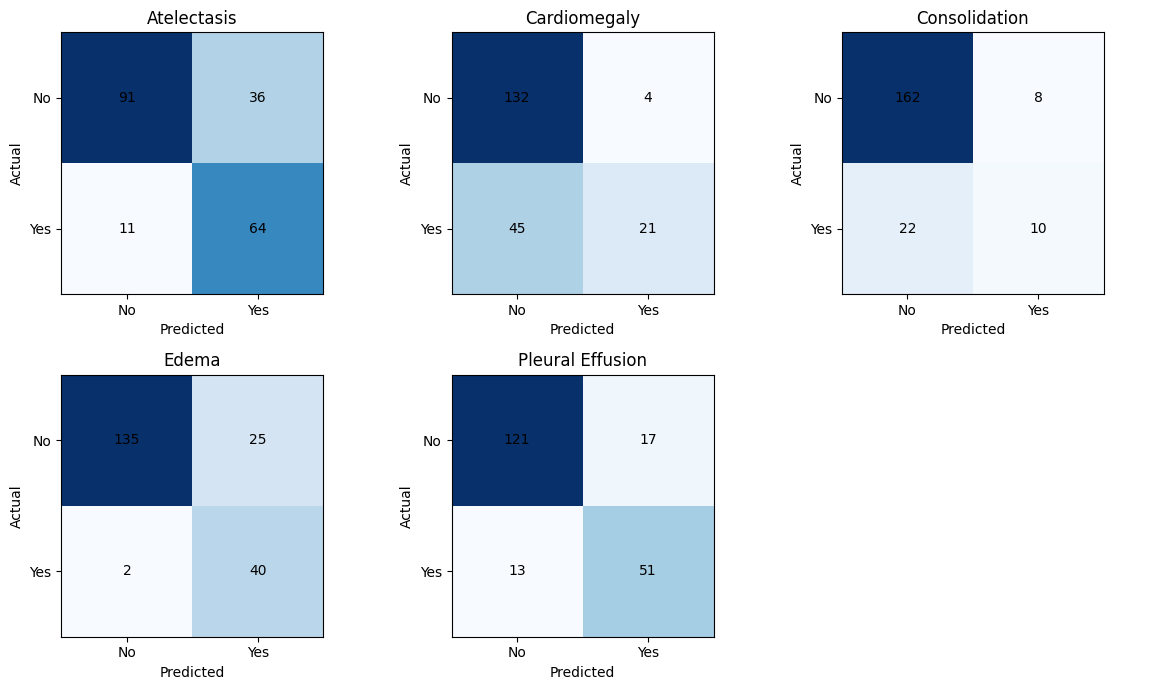

In [14]:
# Plot a confusion matrix
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for j, label in enumerate(LABELS):
    ax = axes.flat[j]
    matrix = confusion_matrix(test_y[:, j].astype(int),
                              (test_probs[:, j] >= thresholds[label]).astype(int),
                              labels=[0, 1])
    ax.imshow(matrix, cmap='Blues')
    for row in range(2):
        for col in range(2):
            ax.text(col, row, str(matrix[row, col]), ha='center', va='center')
    ax.set(title=label, xlabel='Predicted', ylabel='Actual', xticks=[0, 1], yticks=[0, 1],
           xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
axes.flat[-1].axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'confusion_matrices.png', dpi=180)
plt.show()
plt.close(fig)


In [15]:
# Audit one positive example through CLEAR's full concept contributions
audit_label = 'Pleural Effusion'
audit_index = LABELS.index(audit_label)
positive_rows = np.flatnonzero(test_y[:, audit_index] == 1)
example_index = int(positive_rows[0]) if len(positive_rows) else 0
with Image.open(test_df.iloc[example_index]['image_path']) as image:
    audit_image = preprocess(image).unsqueeze(0).to(DEVICE)
with torch.inference_mode():
    audit_feature = F.normalize(model.encode_image(audit_image).float(), dim=-1)
    raw_concept_vector = audit_feature @ projection
    normalizer = raw_concept_vector.norm(dim=-1).item()
    class_weight = head.weight[audit_index].detach()
    contributions = np.empty(bank.num_concepts, dtype='float32')
    for start in range(0, bank.num_concepts, CONCEPT_CHUNK):
        stop = min(start + CONCEPT_CHUNK, bank.num_concepts)
        clip = F.normalize(torch.from_numpy(bank.clip_embeddings[start:stop]).to(DEVICE), dim=1)
        llm = torch.from_numpy(bank.llm_embeddings[start:stop]).to(DEVICE)
        values = (audit_feature @ clip.T).squeeze(0) * (llm @ class_weight) / normalizer
        contributions[start:stop] = values.cpu().numpy()

top_positive = np.argsort(contributions)[-10:][::-1]
top_negative = np.argsort(contributions)[:10]
audit_df = pd.DataFrame([{'direction': direction, 'concept': bank.concepts[int(i)],
                          'logit_contribution': float(contributions[i])}
                         for direction, ids in [('supports', top_positive),
                                                ('opposes', top_negative)] for i in ids])
print('Audited image:', test_df.iloc[example_index]['Path'])
print('Predicted probability:', round(float(test_probs[example_index, audit_index]), 3))
print(audit_df.to_string(index=False))
audit_df.to_csv(RESULTS / 'concept_audit.csv', index=False)


Audited image: CheXpert-v1.0-small/valid/patient64545/study1/view1_frontal.jpg
Predicted probability: 0.594
direction                                                                                   concept  logit_contribution
 supports                                                            layering left pleural effusion            0.000249
 supports                                                      layering left-sided pleural effusion            0.000236
 supports                                                            left layering pleural effusion            0.000234
 supports                                                  moderate, layering left pleural effusion            0.000228
 supports                                                   layering moderate left pleural effusion            0.000227
 supports                                              left layering pleural effusion or aspiration            0.000225
 supports                                          s

In [16]:
# Save metrics, splits, predictions, and measured run settings
history_df.to_csv(RESULTS / 'history.csv', index=False)
pd.DataFrame(all_history).to_csv(RESULTS / 'history_all_seeds.csv', index=False)
seed_summary_df.to_csv(RESULTS / 'seed_summary.csv', index=False)
metrics_by_seed_df.to_csv(RESULTS / 'public_validation_metrics_by_seed.csv', index=False)
aggregate_metrics_df.to_csv(RESULTS / 'public_validation_metrics_mean_std.csv')
metrics_df.to_csv(RESULTS / 'public_validation_metrics.csv')
predictions.to_csv(RESULTS / 'public_validation_predictions.csv', index=False)
for name, frame in [('train', train_df), ('internal_validation', val_df),
                    ('public_validation', test_df)]:
    frame[['Path', 'patient_id', *LABELS]].to_csv(RESULTS / f'{name}_split.csv', index=False)
summary = {
    'model': 'CLEAR full concept representation; frozen encoder and linear head',
    'protocol': 'CheXpert-trained adaptation, not paper-score reproduction',
    'dataset': 'CheXpert frontal images, five findings',
    'final_evaluation': 'public valid.csv, not private CheXpert test',
    'seed_start': SEED, 'number_of_seeds': NUM_SEEDS, 'max_epochs': MAX_EPOCHS,
    'patience': PATIENCE, 'representative_seed': representative_seed,
    'best_epoch': best_epoch, 'learning_rate': LEARNING_RATE,
    'weight_decay': WEIGHT_DECAY, 'image_batch_size': IMAGE_BATCH_SIZE,
    'head_batch_size': HEAD_BATCH_SIZE,
    'uncertain_label_mapping': UNCERTAIN,
    'clear_code_revision': CODE_REVISION,
    'huggingface_revision': HUB_REVISION or 'attached local assets',
    'concept_count': bank.num_concepts,
    'representation_dimension': 4096,
    'projection_check_max_difference': max_difference,
    'projection_minutes': projection_seconds / 60,
    'train_extraction_minutes': train_minutes,
    'validation_extraction_minutes': val_minutes,
    'public_extraction_minutes': test_minutes,
    'head_training_minutes': training_minutes,
    'evaluation_seconds': evaluation_seconds,
    'total_minutes': (time.perf_counter() - RUN_START) / 60,
    'macro_auroc_mean': float(macro_mean),
    'macro_auroc_std': float(macro_std),
    'representative_macro_auroc': float(metrics_df.AUROC.mean()),
}
with open(RESULTS / 'run_summary.json', 'w') as handle:
    json.dump(summary, handle, indent=2)
print(f'Finished. Total time: {summary["total_minutes"]:.1f} minutes')
print('Saved files:', RESULTS)

Finished. Total time: 186.8 minutes
Saved files: /kaggle/working/clear_chexpert_results
